# UIDE · Visión por Computador · Laboratorio 01
## Transfer Learning con ResNet18: fotografías reales y robustez
**Corrección:** extracción con `torch.no_grad()` compatible con entrenamiento posterior de la cabeza.


## 0 · Configuración y reproducibilidad
**Docente:** señalar qué se ejecuta en GPU y por qué fijamos una semilla.

In [3]:
pip install torch torchvision matplotlib numpy scikit-learn

  Using cached torch-2.14.1-cp314-cp314-macosx_14_0_arm64.whl.metadata (39 kB)
  Using cached torchvision-0.29.1-cp314-cp314-macosx_14_0_arm64.whl.metadata (5.7 kB)
  Using cached setuptools-84.0.0-py3-none-any.whl.metadata (6.6 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.3/127.3 MB 25.2 MB/s  0:00:05m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 16.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 23.5 MB/s  0:00:00
Using cached setuptools-84.0.0-py3-none-any.whl (818 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.3 MB 22.8 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 536.2/536.2 kB 3.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [torchvision] [torchvision]

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
import os, random, time, zipfile, urllib.request
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import datasets, models, transforms
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, confusion_matrix

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Dispositivo:', DEVICE, '| PyTorch:', torch.__version__)


Dispositivo: cpu | PyTorch: 2.14.1


## 1 · Fotografías reales y separación de datos (7 min)
**Discusión:** ¿por qué es más difícil clasificar fotografías que dígitos de 8×8? Usamos la partición *train* y *val* proporcionada por el dataset, dividiendo esta última en validación y prueba **sin compartir imágenes**. La prueba no interviene en la selección de hiperparámetros.

Descargando dataset (~45 MB)...
Dataset listo: /Users/jeremyleon/Documents/UIDE/vision-por-computador/semana_1/clase/uidelab12/hymenoptera_data
Clases: ['ants', 'bees'] | Train: 160 | Val: 76 | Test: 77


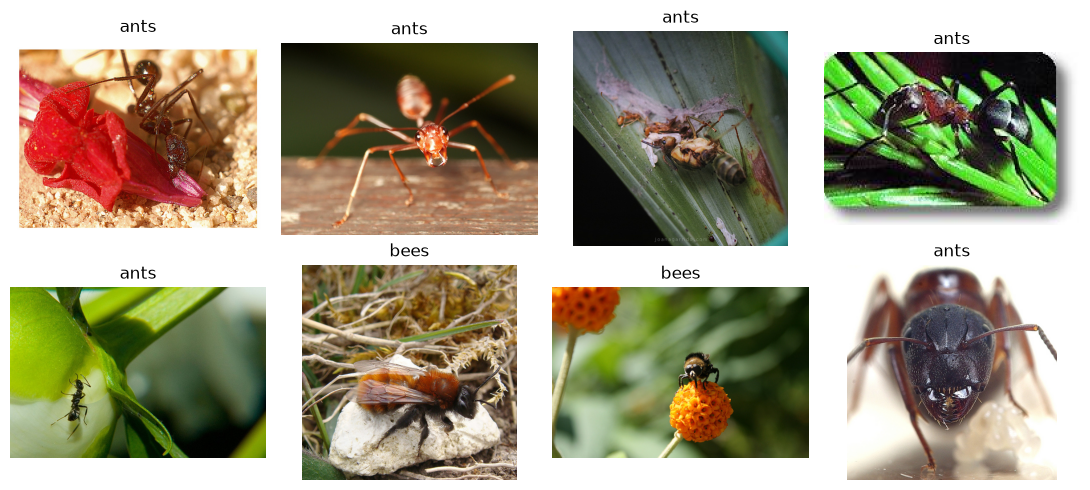

In [7]:
URL = 'https://download.pytorch.org/tutorial/hymenoptera_data.zip'
# /content existe en Colab; en local usamos una carpeta escribible junto al directorio de trabajo
ROOT = Path('/content/uidelab12') if Path('/content').is_dir() else Path.cwd() / 'uidelab12'
ROOT.mkdir(parents=True, exist_ok=True)
ZIP = ROOT / 'hymenoptera_data.zip'
DATA = ROOT / 'hymenoptera_data'
if not (DATA / 'train').exists():
    if not ZIP.exists():
        print('Descargando dataset (~45 MB)...')
        urllib.request.install_opener(urllib.request.build_opener())
        urllib.request.urlretrieve(URL, ZIP)
    with zipfile.ZipFile(ZIP) as z:
        assert all(not Path(m.filename).is_absolute() and '..' not in Path(m.filename).parts for m in z.infolist())
        z.extractall(ROOT)
print('Dataset listo:', DATA)

WEIGHTS = models.ResNet18_Weights.DEFAULT
# Preprocesamiento esperado por los pesos ImageNet de ResNet18
preprocess = WEIGHTS.transforms()
train_base = datasets.ImageFolder(DATA / 'train', transform=preprocess)
heldout_base = datasets.ImageFolder(DATA / 'val', transform=preprocess)
NOMBRES = train_base.classes
assert NOMBRES == heldout_base.classes
rng = np.random.default_rng(SEED)
# 80 ejemplos de entrenamiento por clase para acelerar el laboratorio
train_idx = np.concatenate([rng.choice(np.where(np.array(train_base.targets)==c)[0], size=80, replace=False) for c in range(len(NOMBRES))]).tolist()
# Validación y test estratificados, disjuntos, usando la partición original val
val_idx, test_idx = [], []
for c in range(len(NOMBRES)):
    idx = np.where(np.array(heldout_base.targets)==c)[0]
    idx = rng.permutation(idx)
    corte = len(idx)//2
    val_idx.extend(idx[:corte].tolist()); test_idx.extend(idx[corte:].tolist())
assert set(val_idx).isdisjoint(test_idx)
train_ds = Subset(train_base, train_idx)
val_ds = Subset(heldout_base, val_idx)
test_ds = Subset(heldout_base, test_idx)
print('Clases:', NOMBRES, '| Train:',len(train_ds),'| Val:',len(val_ds),'| Test:',len(test_ds))

# Visualización con imágenes originales, sin normalizar
raw = datasets.ImageFolder(DATA / 'train')
fig, axs = plt.subplots(2,4,figsize=(11,5))
for ax, i in zip(axs.flat, rng.choice(train_idx,8,replace=False)):
    img, label = raw[i]; ax.imshow(img); ax.set_title(NOMBRES[label]); ax.axis('off')
plt.tight_layout(); plt.show()


## 2 · Extracción de características (5–10 min)
**Corrección v1.2.1:** se usa `@torch.no_grad()` y no `@torch.inference_mode()`. Las características se reutilizan para entrenar una capa lineal; los tensores de inferencia no pueden guardarse para su retropropagación.


In [8]:
t0 = time.perf_counter()
modelo = models.resnet18(weights=WEIGHTS)
modelo.fc = nn.Identity()  # salida: vector de 512 características
for p in modelo.parameters(): p.requires_grad_(False)
modelo = modelo.to(DEVICE).eval()

@torch.no_grad()
def extraer(dataset, batch_size=32):
    loader = DataLoader(dataset,batch_size=batch_size,shuffle=False,num_workers=0)
    Xs, ys = [], []
    for imagenes, etiquetas in loader:
        Xs.append(modelo(imagenes.to(DEVICE)).cpu())
        ys.append(etiquetas)
    return torch.cat(Xs).detach().clone(), torch.cat(ys)

X_train,y_train=extraer(train_ds)
X_val,y_val=extraer(val_ds)
X_test,y_test=extraer(test_ds)
print('Características:',tuple(X_train.shape),'| Tiempo total:',round(time.perf_counter()-t0,1),'s')


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/jeremyleon/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:01<00:00, 35.0MB/s]


Características: (160, 512) | Tiempo total: 13.1 s


## 3 · Entrenamiento de la cabeza y curvas (5 min)
**Actividad:** observa la diferencia entre pérdida de entrenamiento y validación. No uses el conjunto de prueba aquí.

Tiempo cabeza: 0.4 s | Accuracy val: 97.4 %


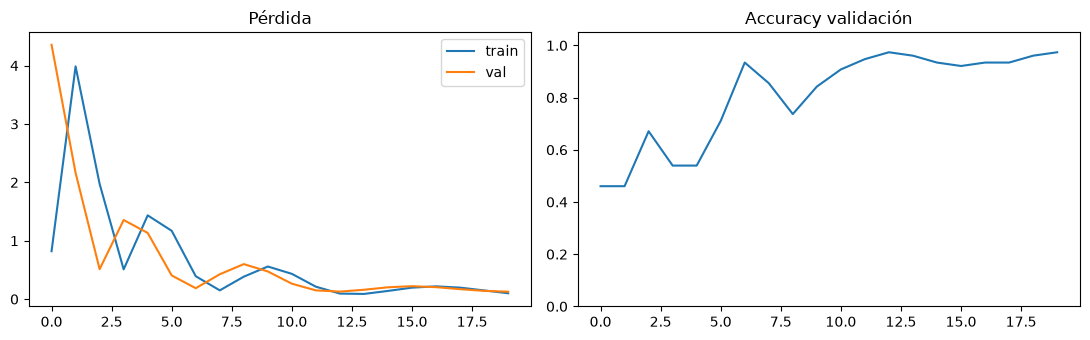

In [9]:
assert not X_train.is_inference(), "X_train sigue siendo tensor de inferencia: ejecuta nuevamente la celda de extracción."
assert not X_val.is_inference(), "X_val sigue siendo tensor de inferencia: ejecuta nuevamente la celda de extracción."

def entrenar_cabeza(lr=0.01, epocas=20):
    torch.manual_seed(SEED)
    cabeza = nn.Linear(X_train.shape[1],len(NOMBRES))
    optim = torch.optim.Adam(cabeza.parameters(),lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    historia={'train':[],'val':[],'acc_val':[]}
    for ep in range(epocas):
        cabeza.train(); optim.zero_grad()
        logits=cabeza(X_train)
        loss=loss_fn(logits,y_train)
        loss.backward(); optim.step()
        cabeza.eval()
        with torch.no_grad():
            lv=loss_fn(cabeza(X_val),y_val).item()
            av=(cabeza(X_val).argmax(1)==y_val).float().mean().item()
        historia['train'].append(loss.item()); historia['val'].append(lv); historia['acc_val'].append(av)
    return cabeza,historia

t0=time.perf_counter()
cabeza,hist=entrenar_cabeza(lr=0.01,epocas=20)
print('Tiempo cabeza:',round(time.perf_counter()-t0,2),'s | Accuracy val:',round(hist['acc_val'][-1]*100,1),'%')
fig,axs=plt.subplots(1,2,figsize=(11,3.5))
axs[0].plot(hist['train'],label='train');axs[0].plot(hist['val'],label='val');axs[0].legend();axs[0].set_title('Pérdida')
axs[1].plot(hist['acc_val']);axs[1].set_ylim(0,1.05);axs[1].set_title('Accuracy validación')
plt.tight_layout();plt.show()


## 4 · Experimento: cambiar el learning rate (5 min)
**Reto:** compara 0.01 y 0.0001. ¿Cuál obtiene mejor validación? Elegimos por **validación**, no por test. El resultado puede variar ligeramente según la ejecución.

In [10]:
cabeza_alt,hist_alt=entrenar_cabeza(lr=0.0001,epocas=20)
print(f"Base: {hist['acc_val'][-1]:.1%} | Alternativa: {hist_alt['acc_val'][-1]:.1%}")
# Regla didáctica simplificada: comparar el último epoch, no optimización exhaustiva.
mejor = cabeza if hist['acc_val'][-1]>=hist_alt['acc_val'][-1] else cabeza_alt
print('Seleccionada:', 'base' if mejor is cabeza else 'alternativa')


Base: 97.4% | Alternativa: 64.5%
Seleccionada: base


## 5 · Evaluación final en test (5 min)
**Interpretación:** el conjunto de prueba se consulta una vez, después de seleccionar la cabeza. El accuracy no es la única métrica importante.

Accuracy test: 96.1%
              precision    recall  f1-score   support

        ants       0.97      0.94      0.96        35
        bees       0.95      0.98      0.96        42

    accuracy                           0.96        77
   macro avg       0.96      0.96      0.96        77
weighted avg       0.96      0.96      0.96        77



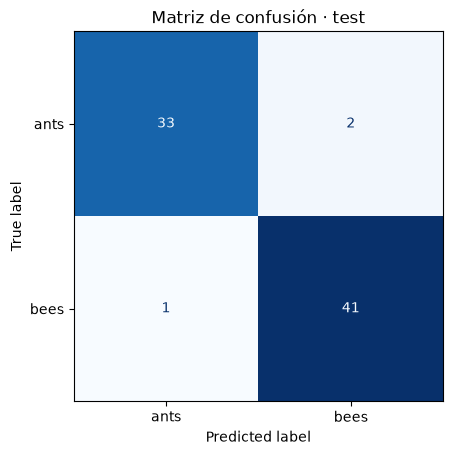

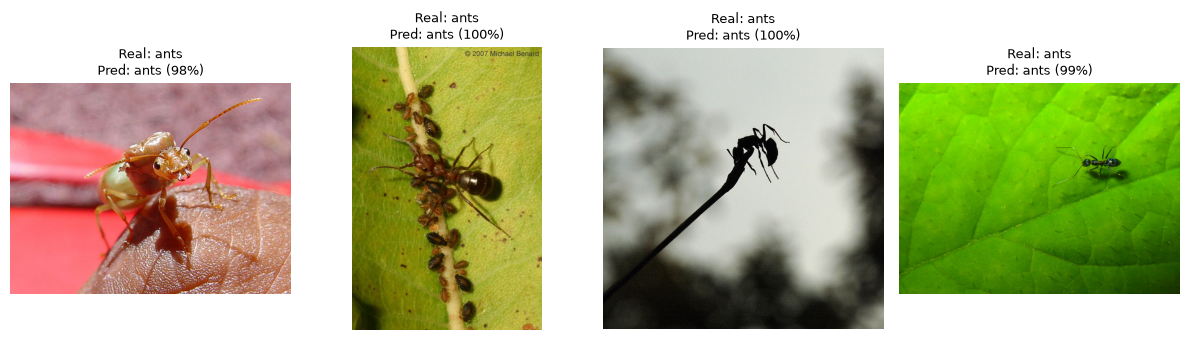

In [ ]:
mejor.eval()
with torch.no_grad():
    logits_test=mejor(X_test)
    probs_test=logits_test.softmax(1)
    pred_test=probs_test.argmax(1).numpy()
real_test=y_test.numpy()
print('Accuracy test:',f'{accuracy_score(real_test,pred_test):.1%}')
print(classification_report(real_test,pred_test,target_names=NOMBRES,zero_division=0))
ConfusionMatrixDisplay.from_predictions(real_test,pred_test,display_labels=NOMBRES,cmap='Blues',colorbar=False)
plt.title('Matriz de confusión · test');plt.show()

# Fotografías reales y predicciones (solo visualización)
raw_test=datasets.ImageFolder(DATA/'val')
fig,axs=plt.subplots(1,4,figsize=(12,3.5))
for ax,k in zip(axs,range(min(4,len(test_idx)))):
    img,etiqueta=raw_test[test_idx[k]]
    ax.imshow(img);ax.axis('off')
    ax.set_title(f'Real: {NOMBRES[etiqueta]}\nPred: {NOMBRES[pred_test[k]]} ({probs_test[k].max():.0%})',fontsize=9)
plt.tight_layout();plt.show()


## 6 · Robustez: ¿qué ocurre si cambia la iluminación? (5 min, opcional)
**No es una segunda prueba independiente:** reutilizamos las imágenes de test transformadas para observar sensibilidad a un cambio de distribución. Evita ajustar el modelo repetidamente usando este resultado.

Accuracy imágenes originales: 96.1%
Accuracy imágenes oscurecidas: 92.2%


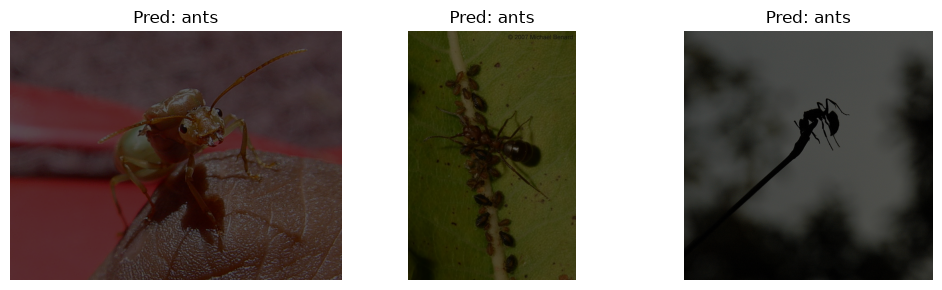

In [12]:
from PIL import ImageEnhance
class ImagenesOscurecidas(Dataset):
    def __init__(self, root, indices, transform, factor=0.35):
        self.raw=datasets.ImageFolder(root)
        self.indices=indices;self.transform=transform;self.factor=factor
    def __len__(self): return len(self.indices)
    def __getitem__(self,k):
        img,y=self.raw[self.indices[k]]
        img=ImageEnhance.Brightness(img).enhance(self.factor)
        return self.transform(img),y

oscuro_ds=ImagenesOscurecidas(DATA/'val',test_idx,preprocess,factor=0.35)
X_osc,y_osc=extraer(oscuro_ds)
with torch.no_grad(): pred_osc=mejor(X_osc).argmax(1).numpy()
print('Accuracy imágenes originales:',f'{accuracy_score(real_test,pred_test):.1%}')
print('Accuracy imágenes oscurecidas:',f'{accuracy_score(y_osc.numpy(),pred_osc):.1%}')
fig,axs=plt.subplots(1,3,figsize=(10,3))
for ax,k in zip(axs,range(3)):
    img,_=oscuro_ds.raw[test_idx[k]]
    ax.imshow(ImageEnhance.Brightness(img).enhance(0.35));ax.axis('off')
    ax.set_title(f'Pred: {NOMBRES[pred_osc[k]]}')
plt.tight_layout();plt.show()


## 7 · Reflexión y conexión con el caso de banano

**Discute en parejas:**
1. ¿Por qué el 100 % en Digits (v1.1) no garantiza resultados similares en fotografías reales?
2. ¿Qué errores son más costosos en una empacadora: rechazar bananos sanos o aceptar bananos defectuosos? ¿Qué métrica priorizarías?
3. ¿Cómo separarías train, validación y test si varias fotografías pertenecen al **mismo racimo o lote**? (Evitar fuga entre grupos).
4. ¿Qué cambios esperarías por iluminación, cámara, fondo o madurez de la fruta?

**Entregable en clase:** captura de la matriz de confusión, resultado del cambio de learning rate y una recomendación de 3 líneas.


